# Data Exploration & EDA: Supply Chain Dataset

## Prediction Tasks

This notebook explores the DataCo Supply Chain dataset for two prediction tasks:

1. **Shipment Duration Prediction** — `Days for shipping (real)` (regression)
2. **Late Delivery Risk Prediction** — `Late_delivery_risk` (binary classification)

## EDA Goals

- Understand dataset shape, schema, and data quality
- Inspect target distributions and class balance
- Examine numeric feature distributions and outliers
- Examine categorical feature cardinality and frequency
- Quantify correlations among numeric features
- Surface feature/target relationships likely to drive model performance
- Look at temporal patterns in orders and shipping

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 60)

## 1. Load Data

In [79]:
df = pd.read_csv("../data/raw/DataCoSupplyChainDataset.csv", encoding="latin1")
print("Shape:", df.shape)
df.head()

Shape: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [81]:
print("Columns:", df.columns.tolist())

Columns: ['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product Status', 'shipping date 

## 2. Data Quality

Quick check for duplicates, missingness, and constant columns before any modelling decisions.

In [82]:
print("Duplicate rows:", df.duplicated().sum())

missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({"missing": missing, "pct": missing_pct})
missing_summary[missing_summary["missing"] > 0].sort_values("missing", ascending=False)

Duplicate rows: 0


,missing,pct
Product Description,180519,100.00
Order Zipcode,155679,86.24
Customer Lname,8,0.00
Customer Zipcode,3,0.00


In [83]:
# Constant / near-constant columns are useless for modelling
nunique = df.nunique().sort_values()
constant_cols = nunique[nunique <= 1].index.tolist()
print("Constant columns:", constant_cols)
nunique.head(15)

Constant columns: ['Product Description', 'Product Status', 'Customer Password', 'Customer Email']


Product Description              0
Product Status                   1
Customer Password                1
Customer Email                   1
Late_delivery_risk               2
Customer Country                 2
Customer Segment                 3
Type                             4
Shipping Mode                    4
Delivery Status                  4
Days for shipment (scheduled)    4
Order Item Quantity              5
Market                           5
Days for shipping (real)         7
Order Status                     9
dtype: int64

## 3. Targets

Inspect both prediction targets — distribution shape for regression, class balance for classification.

In [84]:
TARGET_SHIPPING = "Days for shipping (real)"
TARGET_LATE = "Late_delivery_risk"

print("Shipment Duration Summary:")
print(df[TARGET_SHIPPING].describe())
print("\nLate Delivery Risk Distribution:")
print(df[TARGET_LATE].value_counts(normalize=True).round(3))

Shipment Duration Summary:
count    180519.000000
mean          3.497654
std           1.623722
min           0.000000
25%           2.000000
50%           3.000000
75%           5.000000
max           6.000000
Name: Days for shipping (real), dtype: float64

Late Delivery Risk Distribution:
Late_delivery_risk
1    0.548
0    0.452
Name: proportion, dtype: float64


/var/folders/tn/ydlwf6sn6bb5ccy1g888k1q40000gn/T/ipykernel_6627/1727373794.py:9: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



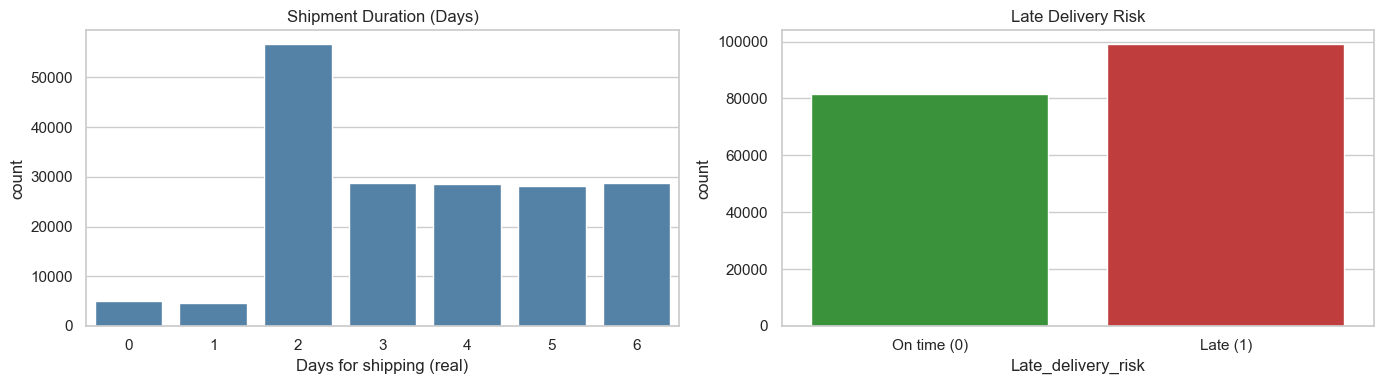

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.countplot(x=TARGET_SHIPPING, data=df, ax=axes[0], color="steelblue")
axes[0].set_title("Shipment Duration (Days)")
axes[0].set_xlabel("Days for shipping (real)")

sns.countplot(x=TARGET_LATE, hue=TARGET_LATE, data=df, ax=axes[1], palette=["#2ca02c", "#d62728"], legend=False)
axes[1].set_title("Late Delivery Risk")
axes[1].set_xticklabels(["On time (0)", "Late (1)"])

plt.tight_layout()
plt.show()

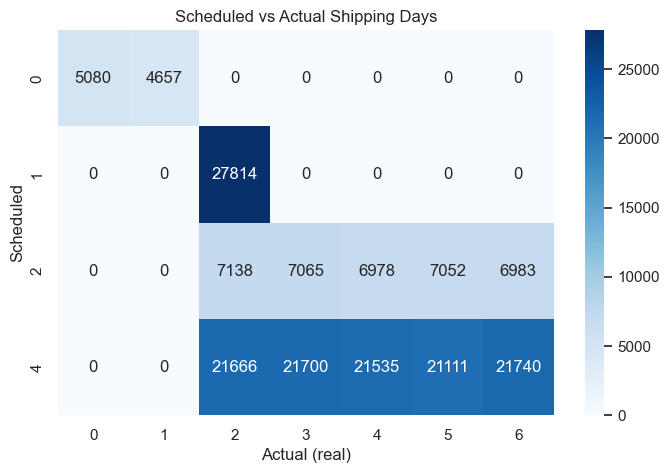

In [86]:
# Scheduled vs actual shipping days — does the schedule line up with reality?
fig, ax = plt.subplots(figsize=(8, 5))
ct = pd.crosstab(df["Days for shipment (scheduled)"], df[TARGET_SHIPPING])
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Scheduled vs Actual Shipping Days")
ax.set_xlabel("Actual (real)")
ax.set_ylabel("Scheduled")
plt.show()

## 4. Numeric Feature Distributions

In [87]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Numeric columns:", len(numeric_cols))
df[numeric_cols].describe().T

Numeric columns: 29


,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.497654,1.623722,0.000000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.000000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180519.0,21.974989,104.433526,-4274.979980,7.000000,31.520000,64.800003,911.799988
Sales per customer,180519.0,183.107609,120.043670,7.490000,104.379997,163.990005,247.399994,1939.989990
Late_delivery_risk,180519.0,0.548291,0.497664,0.000000,0.000000,1.000000,1.000000,1.000000
Category Id,180519.0,31.851451,15.640064,2.000000,18.000000,29.000000,45.000000,76.000000
Customer Id,180519.0,6691.379495,4162.918106,1.000000,3258.500000,6457.000000,9779.000000,20757.000000
Customer Zipcode,180516.0,35921.126914,37542.461122,603.000000,725.000000,19380.000000,78207.000000,99205.000000
Department Id,180519.0,5.443460,1.629246,2.000000,4.000000,5.000000,7.000000,12.000000
Latitude,180519.0,29.719955,9.813646,-33.937553,18.265432,33.144863,39.279617,48.781933


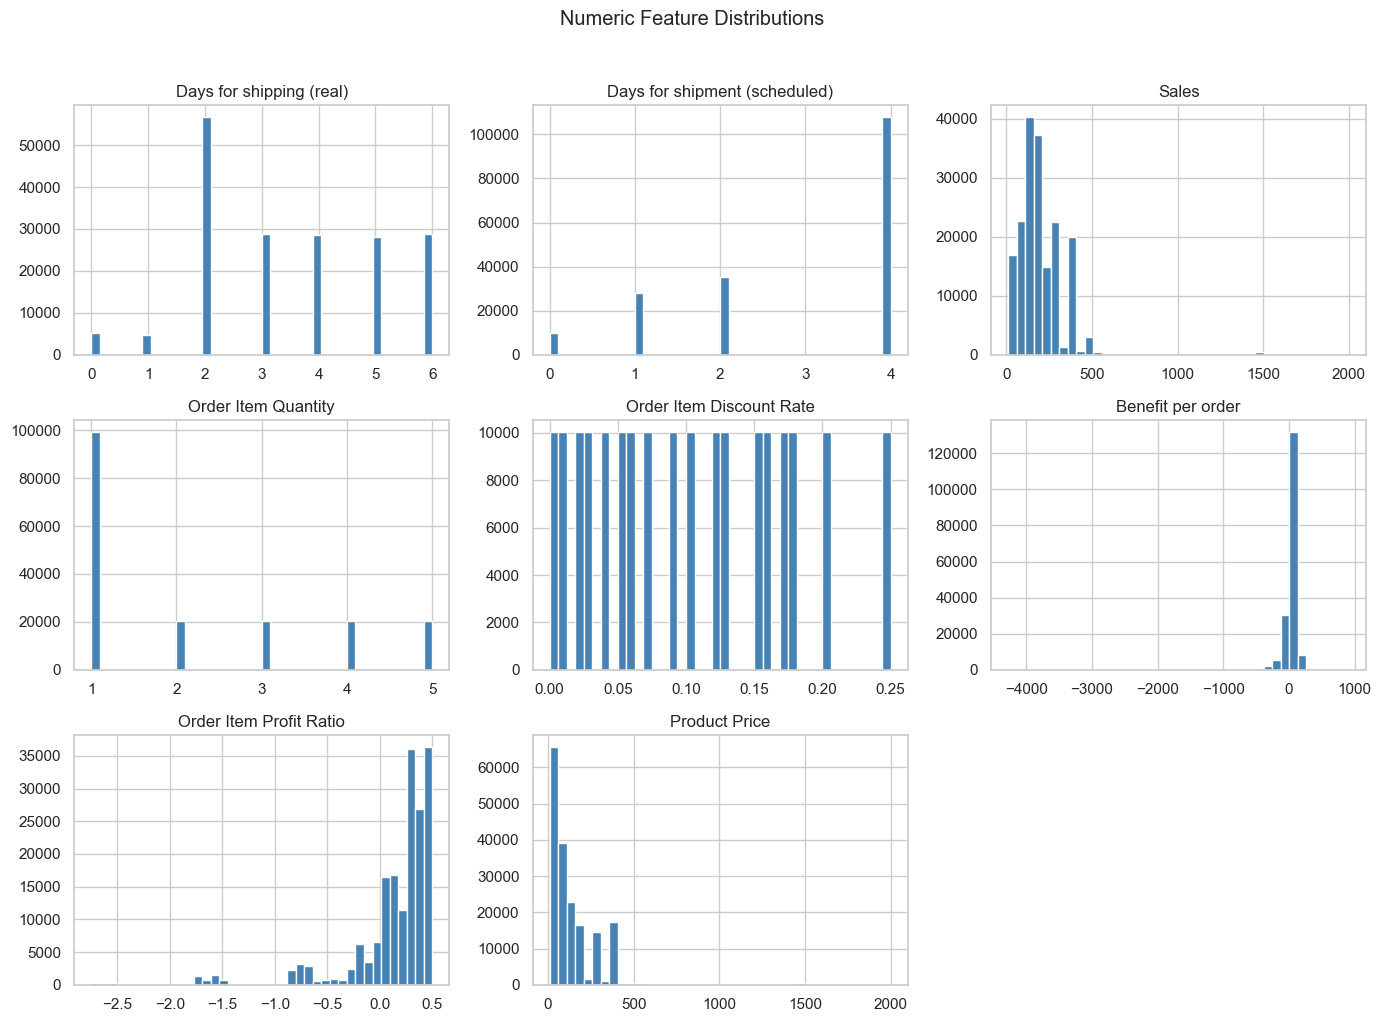

In [88]:
# Histograms for the most informative numeric features
to_plot = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Sales",
    "Order Item Quantity",
    "Order Item Discount Rate",
    "Benefit per order",
    "Order Item Profit Ratio",
    "Product Price",
]
to_plot = [c for c in to_plot if c in df.columns]

df[to_plot].hist(bins=40, figsize=(14, 10), color="steelblue")
plt.suptitle("Numeric Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

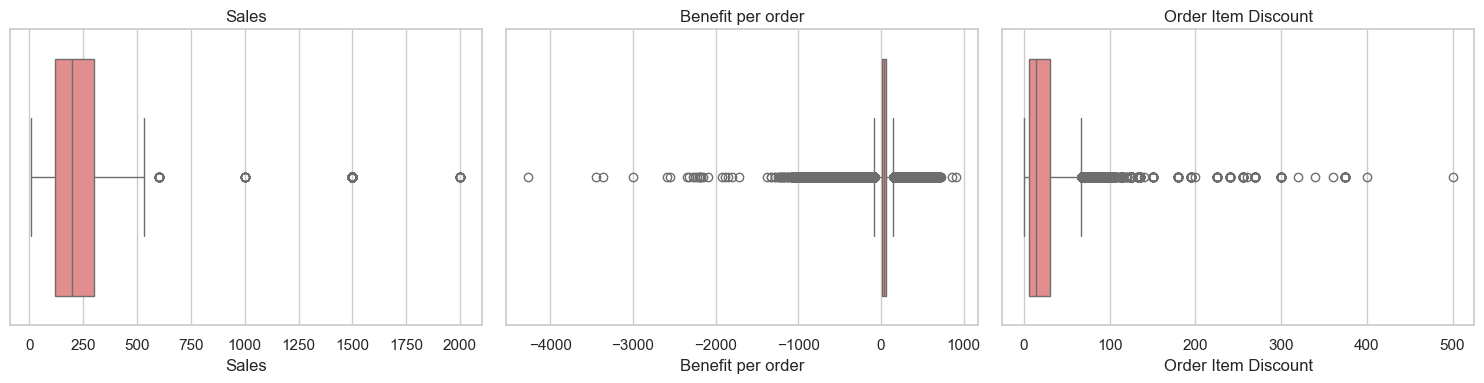

In [89]:
# Boxplots reveal outliers (especially in profit/sales)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Sales", "Benefit per order", "Order Item Discount"]):
    if col in df.columns:
        sns.boxplot(x=df[col], ax=ax, color="lightcoral")
        ax.set_title(col)
plt.tight_layout()
plt.show()

## 5. Correlation Analysis

Identify numeric features most correlated with `Days for shipping (real)` and `Late_delivery_risk`, plus redundancy among predictors.

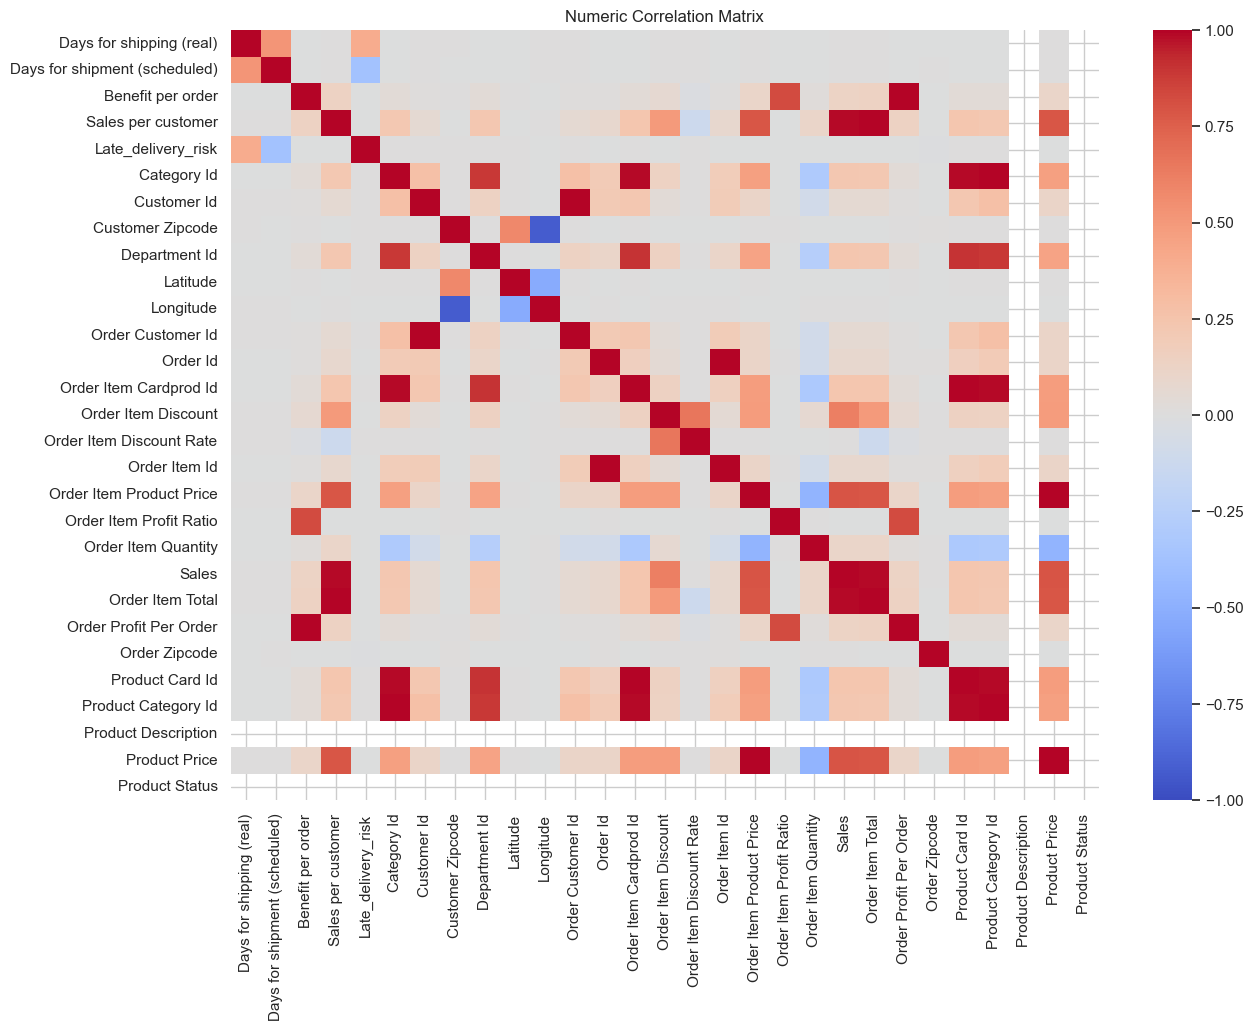

In [90]:
corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, vmin=-1, vmax=1)
ax.set_title("Numeric Correlation Matrix")
plt.show()

In [91]:
# Top correlations with each target
for tgt in [TARGET_SHIPPING, TARGET_LATE]:
    top = corr[tgt].drop(tgt).abs().sort_values(ascending=False).head(10)
    print(f"\nTop |corr| with {tgt}:")
    print(top.round(3))


Top |corr| with Days for shipping (real):
Days for shipment (scheduled)    0.516
Late_delivery_risk               0.401
Order Profit Per Order           0.005
Benefit per order                0.005
Order Item Profit Ratio          0.005
Latitude                         0.004
Longitude                        0.004
Customer Id                      0.003
Order Customer Id                0.003
Order Item Discount              0.002
Name: Days for shipping (real), dtype: float64

Top |corr| with Late_delivery_risk:
Days for shipping (real)         0.401
Days for shipment (scheduled)    0.369
Order Zipcode                    0.014
Sales per customer               0.004
Order Item Total                 0.004
Order Profit Per Order           0.004
Benefit per order                0.004
Sales                            0.004
Customer Zipcode                 0.003
Order Item Profit Ratio          0.002
Name: Late_delivery_risk, dtype: float64


## 6. Categorical Features

In [92]:
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()
card = pd.Series({c: df[c].nunique() for c in categorical_cols}).sort_values(ascending=False)
print("Categorical cardinality:")
print(card)

Categorical cardinality:
order date (DateOrders)       65752
shipping date (DateOrders)    63701
Customer Street                7458
Order City                     3597
Customer Lname                 1109
Order State                    1089
Customer Fname                  782
Customer City                   563
Order Country                   164
Product Image                   118
Product Name                    118
Category Name                    50
Customer State                   46
Order Region                     23
Department Name                  11
Order Status                      9
Market                            5
Type                              4
Delivery Status                   4
Shipping Mode                     4
Customer Segment                  3
Customer Country                  2
Customer Password                 1
Customer Email                    1
dtype: int64


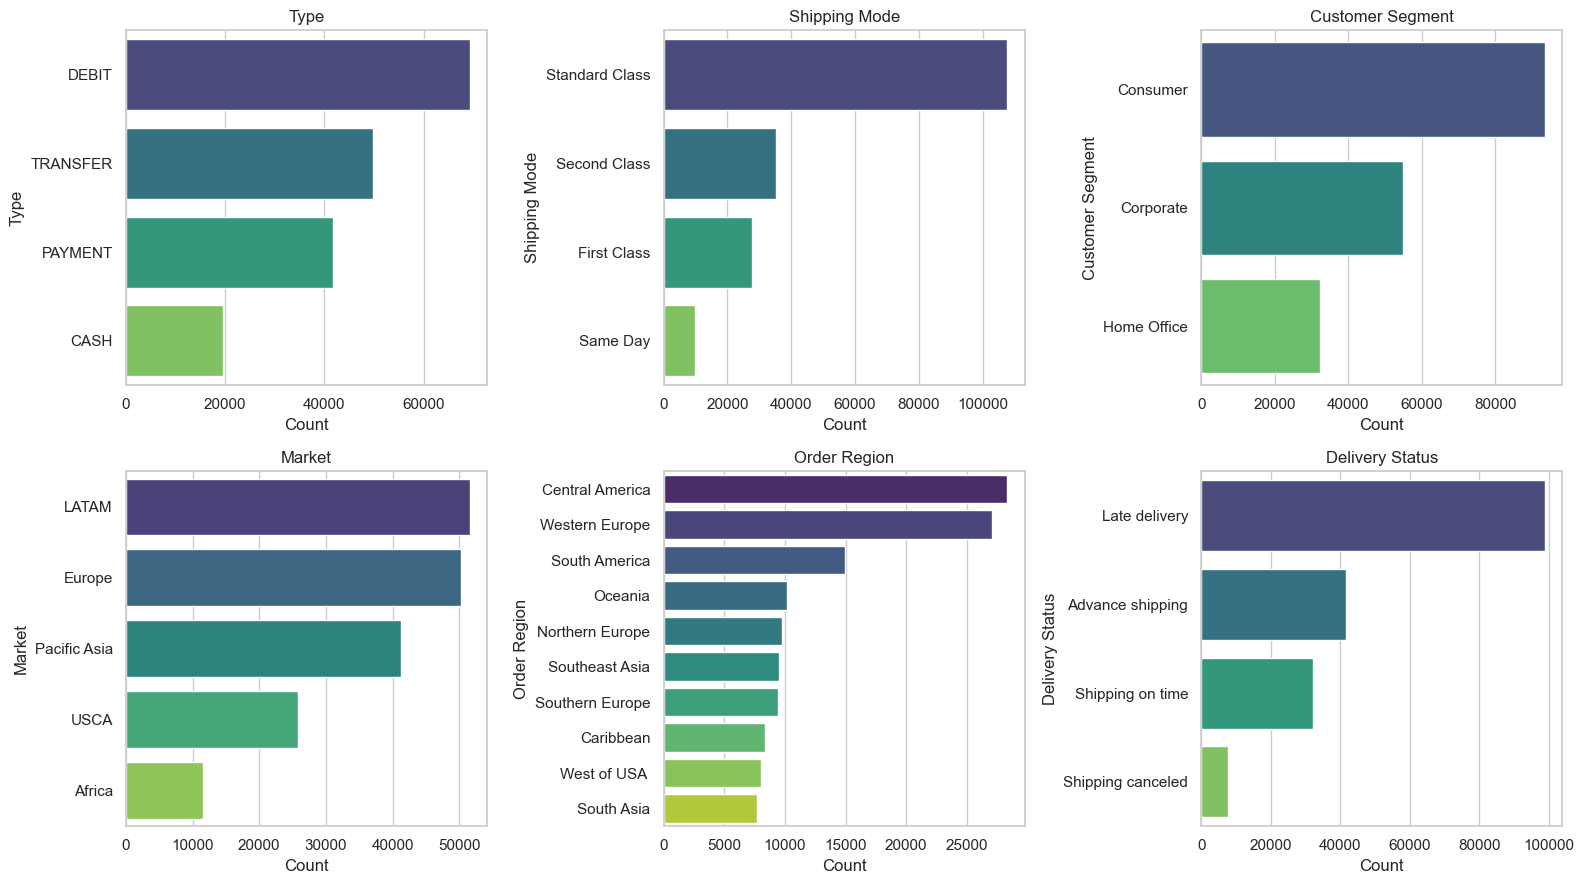

In [93]:
# Distribution of key low-cardinality categoricals
key_cats = ["Type", "Shipping Mode", "Customer Segment", "Market", "Order Region", "Delivery Status"]
key_cats = [c for c in key_cats if c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flatten(), key_cats):
    counts = df[col].value_counts().head(10)
    sns.barplot(x=counts.values, y=counts.index, hue=counts.index, ax=ax, palette="viridis", legend=False)
    ax.set_title(col)
    ax.set_xlabel("Count")
plt.tight_layout()
plt.show()

## 7. Feature ↔ Target Relationships

How does each major feature group break down across targets?

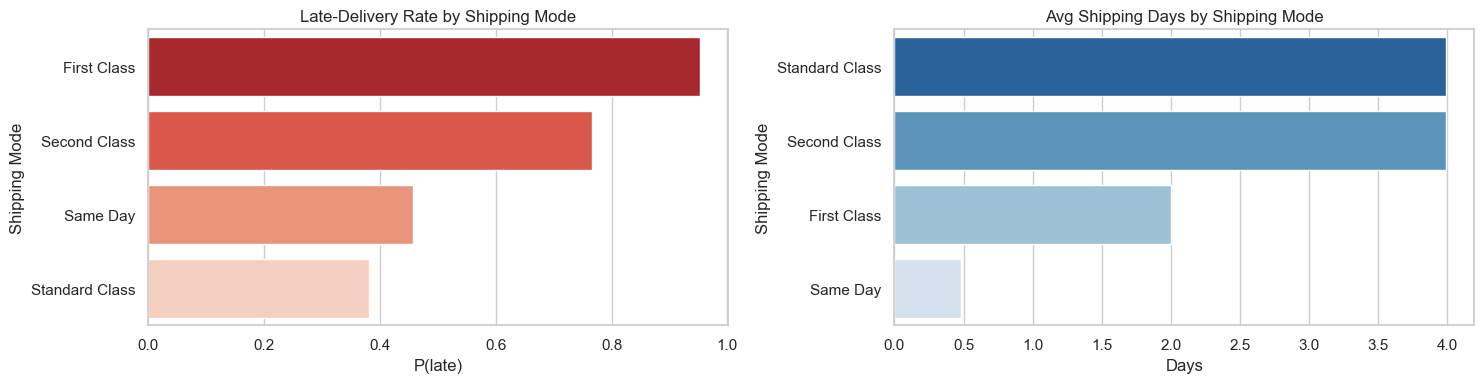

In [94]:
# Late delivery rate by Shipping Mode
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

ship_mode_late = df.groupby("Shipping Mode")[TARGET_LATE].mean().sort_values(ascending=False)
sns.barplot(x=ship_mode_late.values, y=ship_mode_late.index, hue=ship_mode_late.index, ax=axes[0], palette="Reds_r", legend=False)
axes[0].set_title("Late-Delivery Rate by Shipping Mode")
axes[0].set_xlabel("P(late)")

ship_mode_days = df.groupby("Shipping Mode")[TARGET_SHIPPING].mean().sort_values(ascending=False)
sns.barplot(x=ship_mode_days.values, y=ship_mode_days.index, hue=ship_mode_days.index, ax=axes[1], palette="Blues_r", legend=False)
axes[1].set_title("Avg Shipping Days by Shipping Mode")
axes[1].set_xlabel("Days")

plt.tight_layout()
plt.show()

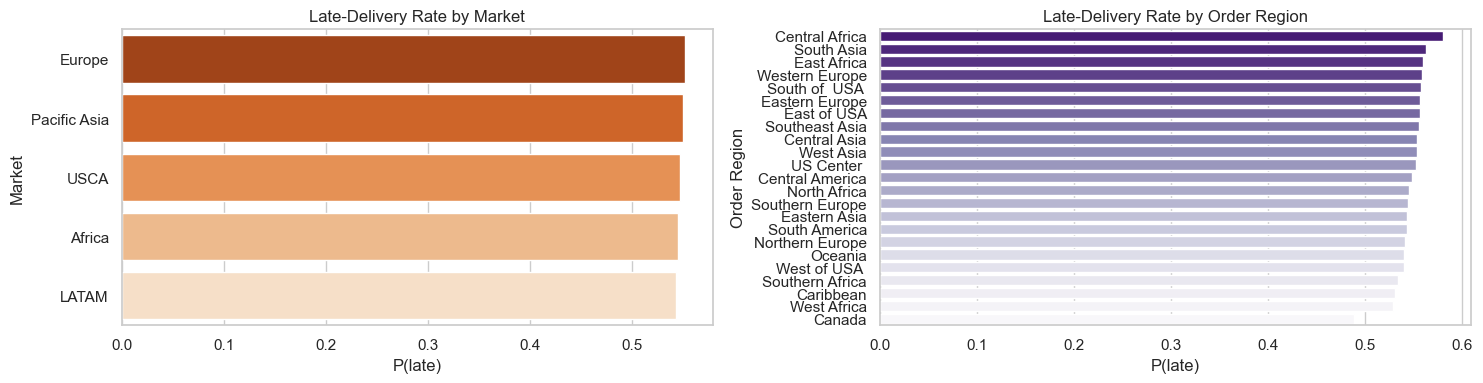

In [95]:
# Late delivery rate by Market and Order Region
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

market_late = df.groupby("Market")[TARGET_LATE].mean().sort_values(ascending=False)
sns.barplot(x=market_late.values, y=market_late.index, hue=market_late.index, ax=axes[0], palette="Oranges_r", legend=False)
axes[0].set_title("Late-Delivery Rate by Market")
axes[0].set_xlabel("P(late)")

region_late = df.groupby("Order Region")[TARGET_LATE].mean().sort_values(ascending=False)
sns.barplot(x=region_late.values, y=region_late.index, hue=region_late.index, ax=axes[1], palette="Purples_r", legend=False)
axes[1].set_title("Late-Delivery Rate by Order Region")
axes[1].set_xlabel("P(late)")

plt.tight_layout()
plt.show()

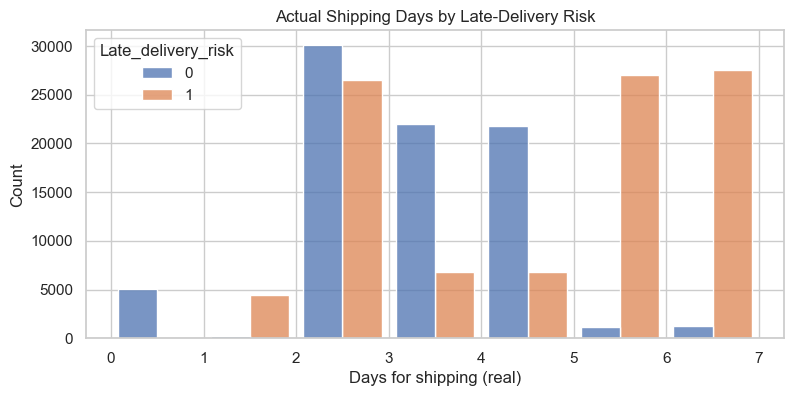

In [96]:
# Distribution of actual shipping days, conditioned on Late_delivery_risk
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(
    data=df, x=TARGET_SHIPPING, hue=TARGET_LATE,
    multiple="dodge", bins=range(0, 8), shrink=0.85, ax=ax
)
ax.set_title("Actual Shipping Days by Late-Delivery Risk")
plt.show()

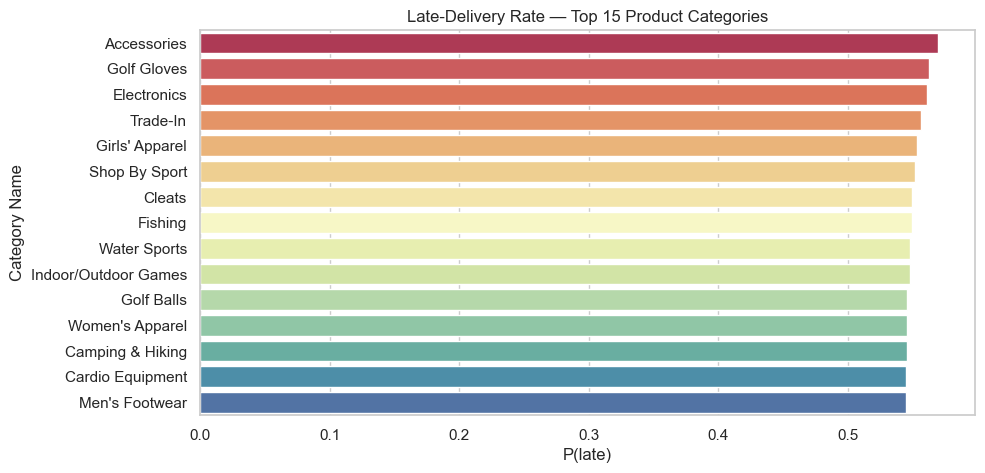

In [97]:
# Top product categories and their late-delivery rates
if "Category Name" in df.columns:
    top_cats = df["Category Name"].value_counts().head(15).index
    cat_late = (
        df[df["Category Name"].isin(top_cats)]
        .groupby("Category Name")[TARGET_LATE]
        .mean()
        .sort_values(ascending=False)
    )
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(x=cat_late.values, y=cat_late.index, hue=cat_late.index, ax=ax, palette="Spectral", legend=False)
    ax.set_title("Late-Delivery Rate — Top 15 Product Categories")
    ax.set_xlabel("P(late)")
    plt.show()

## 8. Temporal Patterns

Order volume and late-delivery rates over time — useful to detect seasonality before feature engineering.

In [98]:
df["order date (DateOrders)"] = pd.to_datetime(df["order date (DateOrders)"], errors="coerce")
df["order_year"] = df["order date (DateOrders)"].dt.year
df["order_month"] = df["order date (DateOrders)"].dt.month
df["order_dayofweek"] = df["order date (DateOrders)"].dt.dayofweek
df["order_hour"] = df["order date (DateOrders)"].dt.hour

print("Date range:", df["order date (DateOrders)"].min(), "->", df["order date (DateOrders)"].max())

Date range: 2015-01-01 00:00:00 -> 2018-01-31 23:38:00


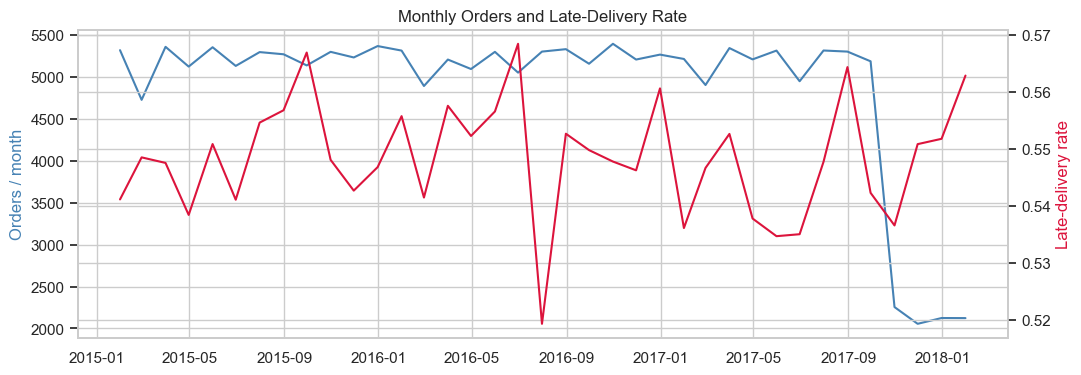

In [99]:
monthly = (
    df.set_index("order date (DateOrders)")
      .resample("ME")
      .agg(orders=("Order Id", "count"), late_rate=(TARGET_LATE, "mean"))
)

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(monthly.index, monthly["orders"], color="steelblue", label="Orders")
ax1.set_ylabel("Orders / month", color="steelblue")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["late_rate"], color="crimson", label="Late rate")
ax2.set_ylabel("Late-delivery rate", color="crimson")
ax1.set_title("Monthly Orders and Late-Delivery Rate")
plt.show()

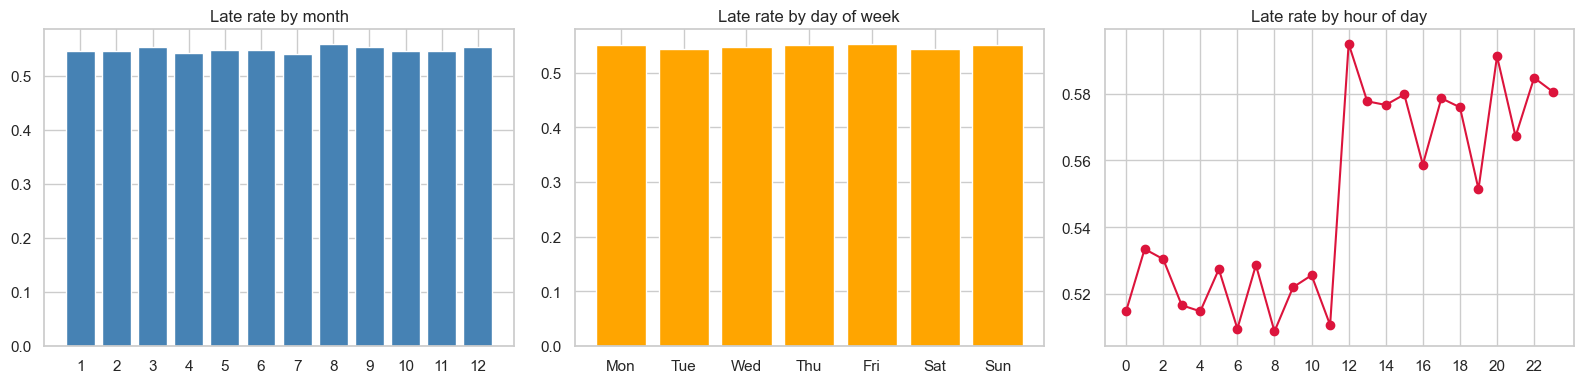

In [100]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

by_month = df.groupby("order_month")[TARGET_LATE].mean()
axes[0].bar(by_month.index, by_month.values, color="steelblue")
axes[0].set_title("Late rate by month")
axes[0].set_xticks(range(1, 13))

by_dow = df.groupby("order_dayofweek")[TARGET_LATE].mean()
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], by_dow.values, color="orange")
axes[1].set_title("Late rate by day of week")

by_hour = df.groupby("order_hour")[TARGET_LATE].mean()
axes[2].plot(by_hour.index, by_hour.values, marker="o", color="crimson")
axes[2].set_title("Late rate by hour of day")
axes[2].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

## 9. Geographic Spread

**Important**: The dataset's `Latitude`/`Longitude` columns are **customer address** coordinates — and `Customer Country` has only 2 unique values (Puerto Rico, USA). Plotting those columns gives a North-America-only map that hides the real order geography.

The cell below uses `Order Country` (plotly choropleth) and `Order Region` (matplotlib bubble chart) to show where orders actually originate, including Central Africa, Western Europe, South Asia, etc.


In [101]:
import plotly.express as px

country_stats = (
    df.groupby("Order Country", as_index=False)
        .agg(orders=("Order Id", "count"),
            late_rate=(TARGET_LATE, "mean"))
)
fig = px.choropleth(
    country_stats,
    locations="Order Country",
    locationmode="country names",
    color="late_rate",
    hover_name="Order Country",
    hover_data={"orders": True, "late_rate": ":.2f"},
    color_continuous_scale="RdYlGn_r",
    title="Late-Delivery Rate by Order Country  (order geography, not customer geography)",
)
fig.update_layout(margin=dict(l=0, r=0, t=40, b=0))
fig.show()
print("Plotly choropleth rendered above.")




print("\nRegion summary:")
print(region_stats.sort_values("orders", ascending=False)
      [["Order Region", "orders", "late_rate"]].to_string(index=False))


/var/folders/tn/ydlwf6sn6bb5ccy1g888k1q40000gn/T/ipykernel_6627/756441530.py:8: DeprecationWarning:

The library used by the *country names* `locationmode` option is changing in an upcoming version. Country names in existing plots may not work in the new version. To ensure consistent behavior, consider setting `locationmode` to *ISO-3*.



Plotly choropleth rendered above.

Region summary:
   Order Region  orders  late_rate
Central America   28341   0.547546
 Western Europe   27109   0.558486
  South America   14935   0.543087
        Oceania   10148   0.540205
Northern Europe    9792   0.540441
 Southeast Asia    9539   0.555299
Southern Europe    9431   0.543845
      Caribbean    8318   0.530777
     South Asia    7731   0.562670
    East of USA    6915   0.556616
      West Asia    6009   0.552837
 Eastern Europe    3920   0.556633
 Central Africa    1677   0.579606
Southern Africa    1157   0.533276
         Canada     959   0.488008
   Central Asia     553   0.553345


## 10. Key Takeaways

- **Class balance**: late deliveries are the majority class (~55%), so accuracy alone is a weak metric — track precision, recall, and F1.
- **Strongest signal for shipping duration** lives in `Days for shipment (scheduled)` and `Shipping Mode`; expect tree models to lean heavily on these.
- **Late-delivery rates differ sharply by Shipping Mode** (Same-Day / First-Class behave very differently from Standard / Second-Class) — a strong categorical predictor.
- **Heavy missingness** in `Order Zipcode` and `Product Description` (>85%) → drop in preprocessing.
- **`Product Status` is constant** across the dataset and adds no signal.
- **Temporal patterns** (month / day-of-week / hour) are mild but non-trivial — worth deriving date features in `feature_engineering.ipynb`.
- **Geographic columns** are high cardinality (cities / countries) and benefit from label encoding for tree-based models.